# Ames Housing Price Prediction | XGBoost & SHAP
An end to end regression pipeline featuring systemic missing value imputation, domain-specific feature engineering, log-transformed target modeling, and SHAP explainability

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBRegressor
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score

In [5]:
df = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')

In [6]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [215]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [216]:
df.isna().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
Street,0
Alley,1369
LotShape,0
LandContour,0
Utilities,0


In [217]:
((df.isna().mean())* 100).sort_values(ascending = False)

,0
PoolQC,99.520548
MiscFeature,96.301370
Alley,93.767123
Fence,80.753425
MasVnrType,59.726027
FireplaceQu,47.260274
LotFrontage,17.739726
GarageQual,5.547945
GarageFinish,5.547945
GarageType,5.547945


In [218]:
df.duplicated().sum()

np.int64(0)

##Data Exploration

In [219]:
# simple pipeline for data quality 6 axis

report = pd.DataFrame({
    'missing%' : (df.isna().mean()*100).round(2),
    'n_unique' : df.nunique(),
    'dtype' : df.dtypes.astype(str)
})

In [220]:
print(report)

               missing%  n_unique    dtype
Id                 0.00      1460    int64
MSSubClass         0.00        15    int64
MSZoning           0.00         5   object
LotFrontage       17.74       110  float64
LotArea            0.00      1073    int64
Street             0.00         2   object
Alley             93.77         2   object
LotShape           0.00         4   object
LandContour        0.00         4   object
Utilities          0.00         2   object
LotConfig          0.00         5   object
LandSlope          0.00         3   object
Neighborhood       0.00        25   object
Condition1         0.00         9   object
Condition2         0.00         8   object
BldgType           0.00         5   object
HouseStyle         0.00         8   object
OverallQual        0.00        10    int64
OverallCond        0.00         9    int64
YearBuilt          0.00       112    int64
YearRemodAdd       0.00        61    int64
RoofStyle          0.00         6   object
RoofMatl   

### EDA & Target Inspection

In [221]:
##checking the target distribution

In [222]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [223]:
print(df['SalePrice'].describe())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [224]:
df['SalePrice'].describe(percentiles= [0.01, 0.05, 0.90, 0.95, 0.99])

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
1%,61815.970000
5%,88000.000000
50%,163000.000000
90%,278000.000000
95%,326100.000000
99%,442567.010000


In [225]:
print(f"skewness: {df['SalePrice'].skew():.4f}")
print(f"kurtosis: {df['SalePrice'].kurt():.4f}")

skewness: 1.8829
kurtosis: 6.5363


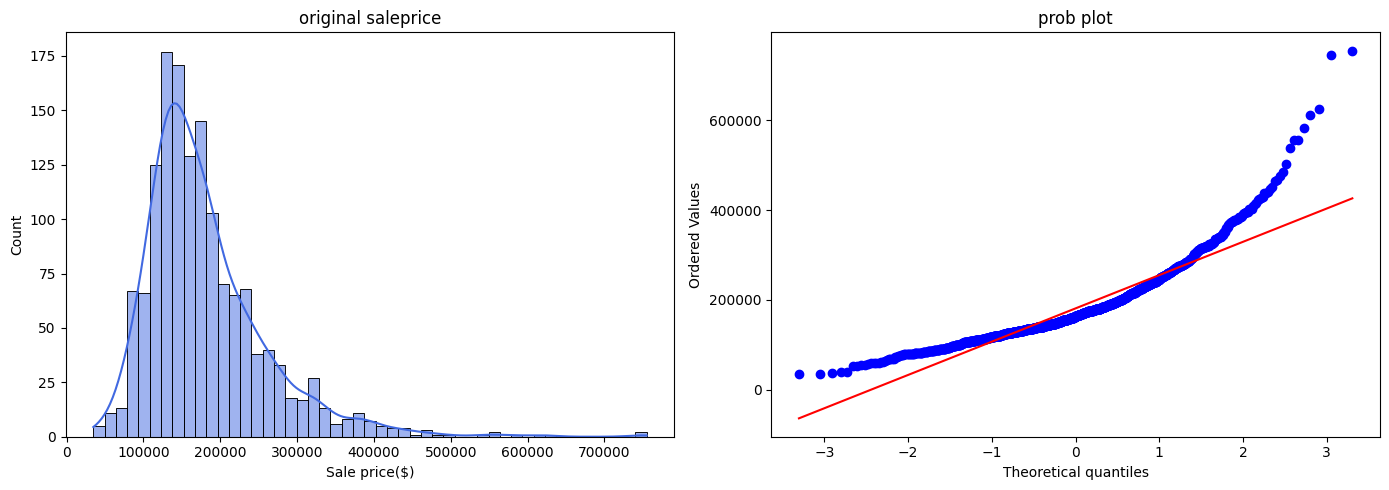

In [226]:
fig, axes = plt.subplots(1,2, figsize = (14,5))

sns.histplot(df['SalePrice'], kde = True, ax = axes[0], color = 'royalblue')
axes[0].set_title('original saleprice')
axes[0].set_xlabel("Sale price($)")

stats.probplot(df['SalePrice'], plot = axes[1])
axes[1].set_title('prob plot')

plt.tight_layout()
plt.show()

##Feature transformation
 i am also using box cox method here along with log transformation , just to check the effect through graphical presentation. 
 but for the final model building and all other step log transformed features are used.

In [227]:
log_sale_price = np.log1p(df['SalePrice'])

In [228]:
from scipy.stats import boxcox
box_cox_sale_price , lam = boxcox(df['SalePrice'])
box_cox_sale_price = pd.Series(box_cox_sale_price)

In [229]:
print(f"skewness after log1p: {log_sale_price.skew():.4f}")
print(f"kurtosis after log1p: {log_sale_price.kurt():.4f}")

skewness after log1p: 0.1213
kurtosis after log1p: 0.8095


In [230]:
print(f"skewness after box-cox: {box_cox_sale_price.skew():.4f}")
print(f"kurtosis after box-cox: {box_cox_sale_price.kurt():.4f}")

skewness after box-cox: -0.0087
kurtosis after box-cox: 0.8779


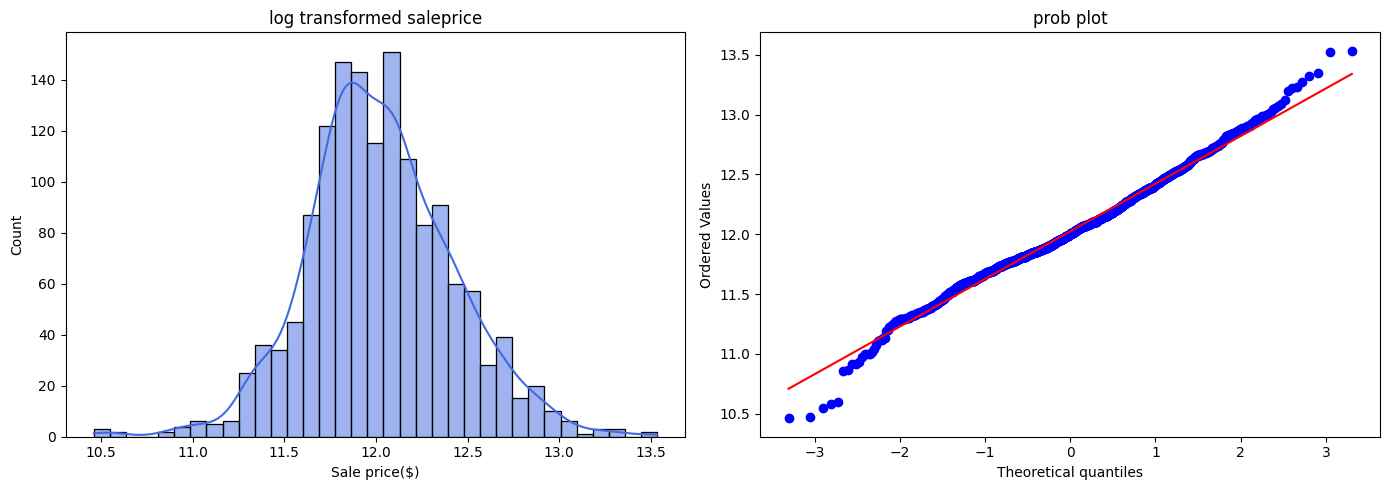

In [231]:
fig, axes = plt.subplots(1,2, figsize = (14,5))

sns.histplot(log_sale_price, kde = True, ax = axes[0], color = 'royalblue')
axes[0].set_title('log transformed saleprice')
axes[0].set_xlabel("Sale price($)")

stats.probplot(log_sale_price, plot = axes[1])
axes[1].set_title('prob plot')

plt.tight_layout()
plt.show()

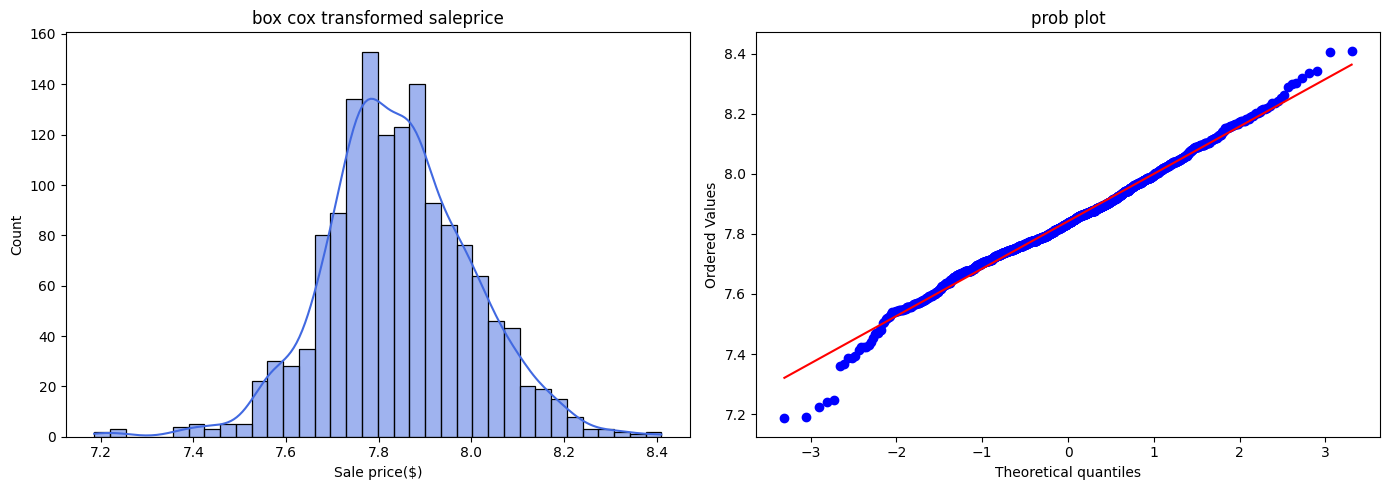

In [232]:
fig, axes = plt.subplots(1,2, figsize = (14,5))

sns.histplot(box_cox_sale_price, kde = True, ax = axes[0], color = 'royalblue')
axes[0].set_title('box cox transformed saleprice')
axes[0].set_xlabel("Sale price($)")

stats.probplot(box_cox_sale_price, plot = axes[1])
axes[1].set_title('prob plot')

plt.tight_layout()
plt.show()

###Multivariate analysis
(correlational heatmap)

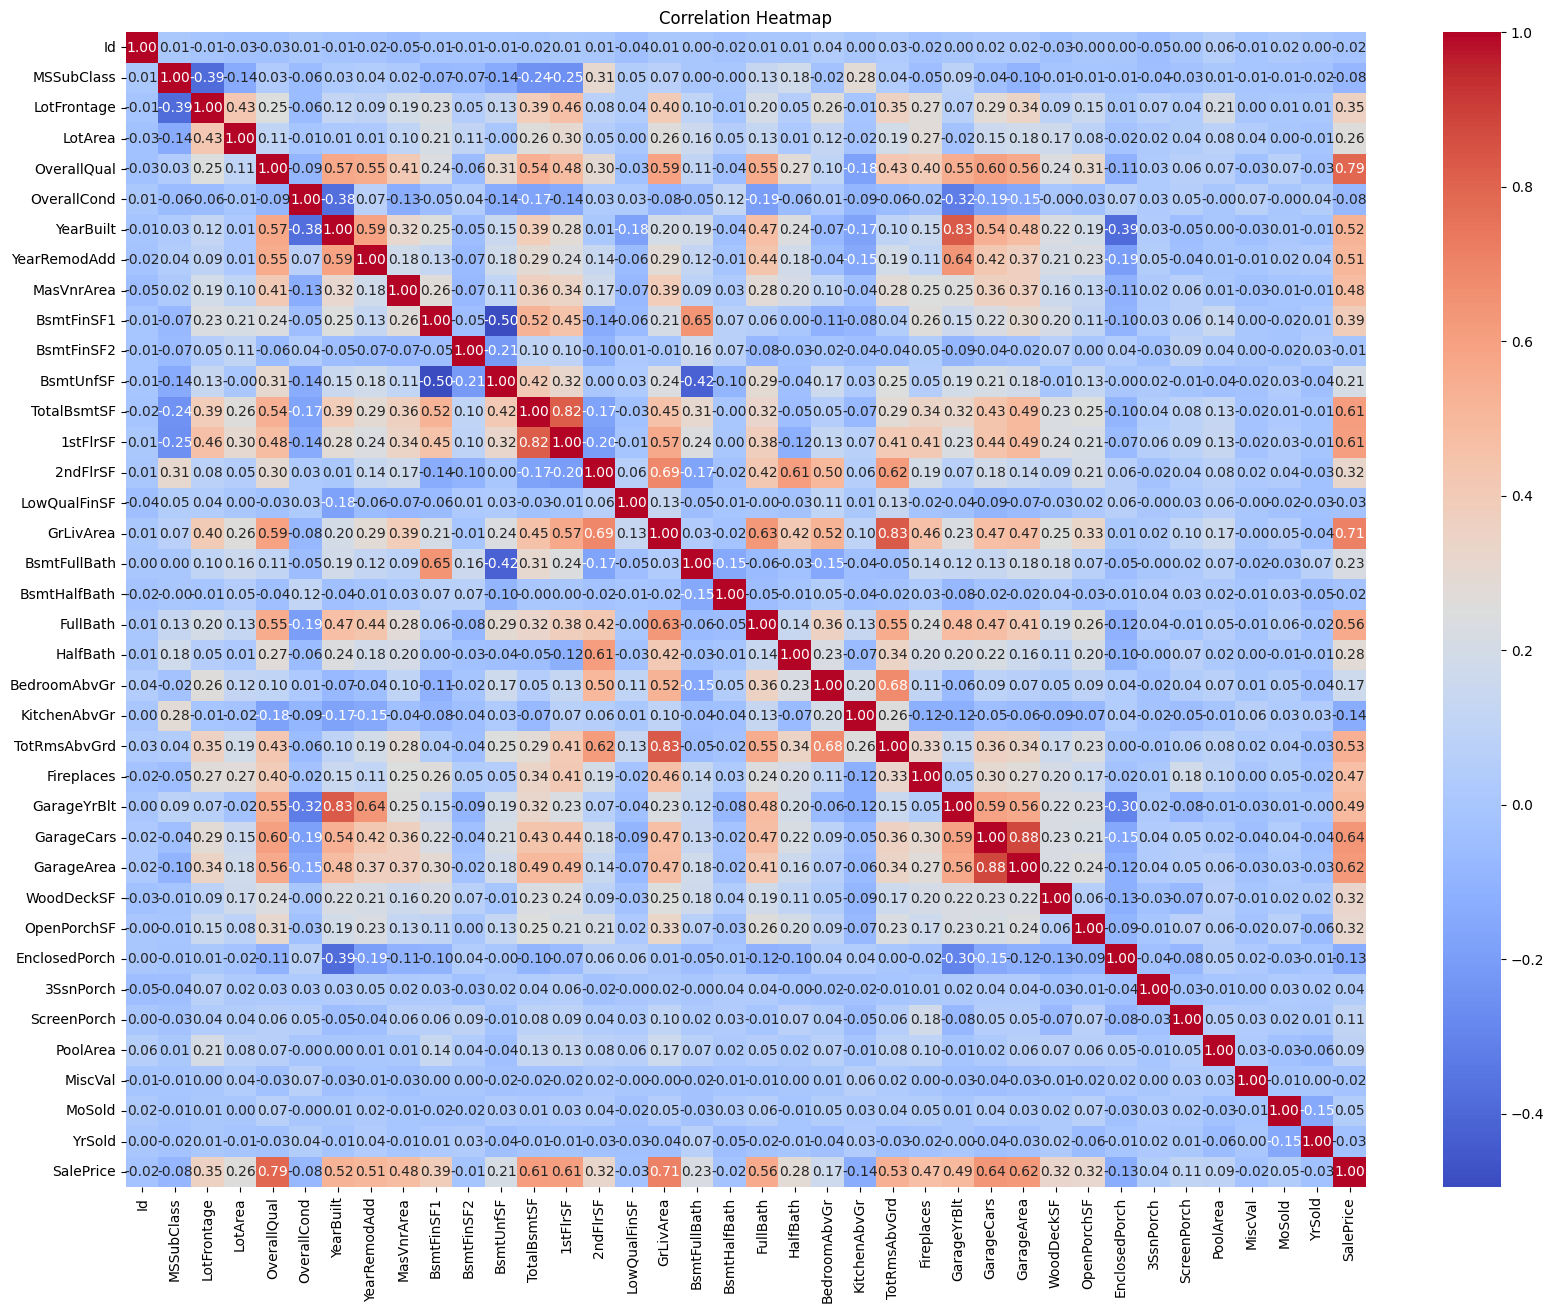

In [233]:
#selecting only numerical columns
numeric_df = df.select_dtypes(include = 'number')

# correlation matrix
corr_matrix = numeric_df.corr()

plt.figure(figsize = (20,15))

sns.heatmap(
    corr_matrix,
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f'
)

plt.title('Correlation Heatmap')

plt.show()

###Handling missing values

In [234]:
(df.isna().mean() * 100).sort_values(ascending = False)

,0
PoolQC,99.520548
MiscFeature,96.301370
Alley,93.767123
Fence,80.753425
MasVnrType,59.726027
FireplaceQu,47.260274
LotFrontage,17.739726
GarageQual,5.547945
GarageFinish,5.547945
GarageType,5.547945


MCAR - 'LotFrontage', 'GarageYrBlt', 'MasVnrArea', 'Electrical' - fill with knn imputer( because these house have these features but their values are not availabel so we can't fill them with 0)


Structural Missing - rest all missing columns(i.e. these house don't have that peticular feature) - fill with None

In [235]:
amenity_None_col = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'GarageQual', 'GarageFinish', 'GarageType', 'GarageCond', 'BsmtFinType2' ,	'BsmtExposure', 'BsmtCond', 'BsmtQual', 'BsmtFinType1', 'FireplaceQu', 'Electrical']

In [236]:
df[amenity_None_col] = df[amenity_None_col].fillna('None')
test_df[amenity_None_col] = test_df[amenity_None_col].fillna('None')

In [237]:
col_to_impute_knn = ['LotFrontage', 'GarageYrBlt', 'MasVnrArea']

In [238]:
imputer = KNNImputer(n_neighbors= 5)

In [239]:
df[col_to_impute_knn] = imputer.fit_transform(df[col_to_impute_knn])
test_df[col_to_impute_knn] = imputer.transform(test_df[col_to_impute_knn])

In [240]:
((test_df.isna().mean())*100).sort_values(ascending = False)

,0
MSZoning,0.27416
Utilities,0.13708
BsmtHalfBath,0.13708
BsmtFullBath,0.13708
Functional,0.13708
GarageCars,0.06854
BsmtUnfSF,0.06854
BsmtFinSF2,0.06854
Exterior2nd,0.06854
BsmtFinSF1,0.06854


In [241]:
# filling the null values which didn't appear in train dataset i.e. only seen in test dataset
# for categorical columns = imputing None with mode learned from train dataset
# for numerical columns = impuring None with median learned from trian dataset


train_cat_modes = df.select_dtypes(include = ['object']).mode().iloc[0]
train_num_medians = df.select_dtypes(include=[np.number]).median()

test_cat_cols = test_df.select_dtypes(include=['object']).columns
test_num_cols = test_df.select_dtypes(include=[np.number]).columns

test_df[test_cat_cols] = test_df[test_cat_cols].fillna(train_cat_modes)
test_df[test_num_cols] = test_df[test_num_cols].fillna(train_num_medians)

###Ourlier detection & teatment -
not to be done on test datasset

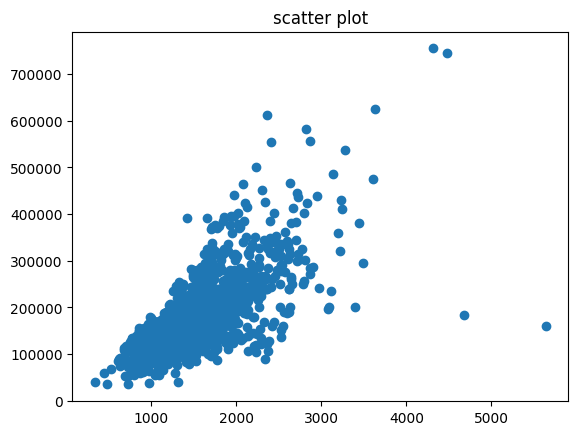

In [242]:
plt.scatter(df['GrLivArea'], df['SalePrice'])
plt.title('scatter plot')
plt.show()

In [243]:
df[(df['GrLivArea']>4000) & (df['SalePrice']<300000)].index

Index([523, 1298], dtype='int64')

In [244]:
df.drop(df[(df['GrLivArea']>4000) & (df['SalePrice']<300000)].index, inplace= True)

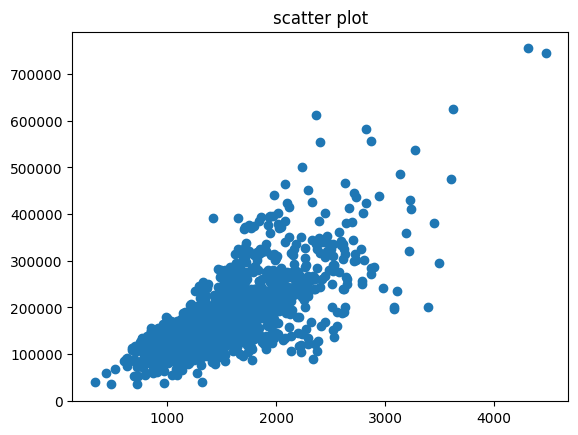

In [245]:
plt.scatter(df['GrLivArea'], df['SalePrice'])
plt.title('scatter plot')
plt.show()

###Feature Engineering & Preprocessing

In [246]:
df['TotalHouseSF'] = df['TotalBsmtSF'] + df['GrLivArea']
df['TotalBathrooms'] = df['FullBath'] + df['HalfBath'] * 0.5 + df['BsmtFullBath'] + df['BsmtHalfBath'] * 0.5
df['TotalPorchArea'] = df['WoodDeckSF'] + df['OpenPorchSF'] + df['EnclosedPorch'] +df['3SsnPorch'] + df['ScreenPorch']
df['AgeAtSale'] = df['YrSold'] - df['YearBuilt']

test_df['TotalHouseSF'] = test_df['TotalBsmtSF'] + test_df['GrLivArea']
test_df['TotalBathrooms'] = test_df['FullBath'] + test_df['HalfBath'] * 0.5 + test_df['BsmtFullBath'] + test_df['BsmtHalfBath'] * 0.5
test_df['TotalPorchArea'] = test_df['WoodDeckSF'] + test_df['OpenPorchSF'] + test_df['EnclosedPorch'] + test_df['3SsnPorch'] + test_df['ScreenPorch']
test_df['AgeAtSale'] = test_df['YrSold'] - test_df['YearBuilt']


In [247]:
df.drop(['1stFlrSF', '2ndFlrSF', 'TotalBsmtSF','GrLivArea','LowQualFinSF', 'FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', 'YrSold', 'YearBuilt', '3SsnPorch', 'ScreenPorch'], axis = 1, inplace= True)

test_df.drop(['1stFlrSF', '2ndFlrSF', 'TotalBsmtSF','GrLivArea','LowQualFinSF', 'FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', 'YrSold', 'YearBuilt', '3SsnPorch', 'ScreenPorch'], axis = 1, inplace= True)

In [248]:
#label encoding -  LandSlope, OverallQual, OverallCond, LotShape, ExterQual, ExterCond, BsmtCond, BsmtQual, BsmtExposure, BsmtFinType1, BsmtFinType2, HeatingQC, KitchenQual, Functional, FireplaceQu, GarageFinish, GarageQual, GarageCond, PavedDrive, PoolQC, Fence,

#OHE - MSSubClass, MSZoning, Street, Alley, LandContour, Utilities, LotConfig, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, Foundation, Heating, CentralAir, Electrical, GarageType, MiscFeature, SaleCondition, SaleType

###Handling categorical values - via -
Ordinal encoding &


One Hot Encoding

In [249]:
Ordinal_cols = ['LandSlope', 'OverallQual', 'OverallCond', 'LotShape', 'ExterQual', 'ExterCond', 'BsmtCond', 'BsmtQual', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence']
for col in Ordinal_cols:
  print(f'unique values for {col}:{df[col].value_counts()} \n')


unique values for LandSlope:LandSlope
Gtl    1380
Mod      65
Sev      13
Name: count, dtype: int64 

unique values for OverallQual:OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      20
10     16
2       3
1       2
Name: count, dtype: int64 

unique values for OverallCond:OverallCond
5    819
6    252
7    205
8     72
4     57
3     25
9     22
2      5
1      1
Name: count, dtype: int64 

unique values for LotShape:LotShape
Reg    925
IR1    483
IR2     41
IR3      9
Name: count, dtype: int64 

unique values for ExterQual:ExterQual
TA    906
Gd    488
Ex     50
Fa     14
Name: count, dtype: int64 

unique values for ExterCond:ExterCond
TA    1280
Gd     146
Fa      28
Ex       3
Po       1
Name: count, dtype: int64 

unique values for BsmtCond:BsmtCond
TA      1309
Gd        65
Fa        45
None      37
Po         2
Name: count, dtype: int64 

unique values for BsmtQual:BsmtQual
TA      649
Gd      618
Ex      119
None     37
Fa       35
Name: count, dtyp

In [250]:
Nominal_cols = ['MSSubClass', 'MSZoning' , 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'GarageType', 'MiscFeature', 'SaleCondition', 'SaleType']
for col in Nominal_cols:
  print(f'unique values for {col}:{df[col].value_counts()} \n')

unique values for MSSubClass:MSSubClass
20     536
60     297
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64 

unique values for MSZoning:MSZoning
RL         1149
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64 

unique values for Street:Street
Pave    1452
Grvl       6
Name: count, dtype: int64 

unique values for Alley:Alley
None    1367
Grvl      50
Pave      41
Name: count, dtype: int64 

unique values for LandContour:LandContour
Lvl    1311
Bnk      61
HLS      50
Low      36
Name: count, dtype: int64 

unique values for Utilities:Utilities
AllPub    1457
NoSeWa       1
Name: count, dtype: int64 

unique values for LotConfig:LotConfig
Inside     1051
Corner      262
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64 

unique values for Neighborhood:Neighborhood
NAmes      225
CollgCr    150
OldTow

In [251]:
# proper Ordinal encoding to be done for = all except PoolQC, Fence(binary encoding for these 2 columns because they dont have much variance)

# proper OHE to be done for = all except Utilities, Condition2, Street, RoofMatl, Heating (drop these columns)
#                                         Alley, Electrical, MiscFeature (Binary encoding)

In [252]:
df = df.drop(columns = ['Id', 'Utilities', 'Condition2','Street', 'RoofMatl', 'Heating'])
test_df = test_df.drop(columns = ['Id', 'Utilities', 'Condition2','Street', 'RoofMatl', 'Heating'])

In [253]:
# creating Binary encoding for columns not having significant variance

df['HasFence'] = (df['Fence'] != 'None').astype(int)
df['HasPool'] = (df['PoolQC'] != 'None').astype(int)
df['HasAlley'] = (df['Alley'] != 'None').astype(int)
df['HasMiscFeature'] = (df['MiscFeature'] != None).astype(int)
df['NewElectrSys'] = (df['Electrical'] == 'SBrkr').astype(int)
df = df.drop(columns = ['Fence', 'PoolQC', 'Alley', 'MiscFeature', 'Electrical'])

test_df['HasFence'] = (test_df['Fence'] != 'None').astype(int)
test_df['HasPool'] = (test_df['PoolQC'] != 'None').astype(int)
test_df['HasAlley'] = (test_df['Alley'] != 'None').astype(int)
test_df['HasMiscFeature'] = (test_df['MiscFeature'] != None).astype(int)
test_df['NewElectrSys'] = (test_df['Electrical'] == 'SBrkr').astype(int)
test_df = test_df.drop(columns = ['Fence', 'PoolQC', 'Alley', 'MiscFeature', 'Electrical'])

In [254]:
col_for_OHE = ['MSSubClass', 'MSZoning', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'BldgType', 'HouseStyle', 'RoofStyle', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'CentralAir', 'GarageType', 'SaleCondition', 'SaleType']
for col in col_for_OHE:
  print(f'unique values for {col}:{df[col].value_counts()} \n')

unique values for MSSubClass:MSSubClass
20     536
60     297
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64 

unique values for MSZoning:MSZoning
RL         1149
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64 

unique values for LandContour:LandContour
Lvl    1311
Bnk      61
HLS      50
Low      36
Name: count, dtype: int64 

unique values for LotConfig:LotConfig
Inside     1051
Corner      262
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64 

unique values for Neighborhood:Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards     98
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17


In [255]:
# merging rare values from nominal columns at one places per column

def grouping_rare_categories(df, columns, threshold = 10, fill_value = 'Other'):
  for col in columns:
    counts = df[col].value_counts()
    rare_labels = counts[counts < threshold].index
    df[col] = df[col].replace(rare_labels, fill_value)
  return df

df = grouping_rare_categories(df, col_for_OHE, threshold = 10, fill_value = 'Other')
test_df = grouping_rare_categories(test_df, col_for_OHE, threshold = 10, fill_value = 'Other')

In [256]:
## next step - do OHE and Ordinal Encoding

In [257]:
# OHE -
#encoded_df = pd.get_dummies(df, columns = col_for_OHE, drop_first = True, dtype= int)
#encoded_df.head()

In [258]:
# OHE
encoder = OneHotEncoder(handle_unknown = 'ignore', sparse_output = False)
encoder.set_output(transform = 'pandas')

df[col_for_OHE] = df[col_for_OHE].astype(str)
test_df[col_for_OHE] = test_df[col_for_OHE].astype(str)

df_dummies = encoder.fit_transform(df[col_for_OHE])
test_df_dummies = encoder.transform(test_df[col_for_OHE])

df_clean = df.drop(columns = col_for_OHE)
test_df_clean = test_df.drop(columns = col_for_OHE)

encoded_df = pd.concat([df_dummies, df_clean], axis = 1)
encoded_test_df = pd.concat([test_df_dummies, test_df_clean], axis = 1)

In [210]:
Ordinal_values = ['LandSlope', 'OverallQual', 'OverallCond', 'LotShape', 'ExterQual', 'ExterCond', 'BsmtCond', 'BsmtQual', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive']
for col in Ordinal_values:
  print(f'unique values for {col}:{df[col].value_counts()} \n')


unique values for LandSlope:LandSlope
Gtl    1380
Mod      65
Sev      13
Name: count, dtype: int64 

unique values for OverallQual:OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      20
10     16
2       3
1       2
Name: count, dtype: int64 

unique values for OverallCond:OverallCond
5    819
6    252
7    205
8     72
4     57
3     25
9     22
2      5
1      1
Name: count, dtype: int64 

unique values for LotShape:LotShape
Reg    925
IR1    483
IR2     41
IR3      9
Name: count, dtype: int64 

unique values for ExterQual:ExterQual
TA    906
Gd    488
Ex     50
Fa     14
Name: count, dtype: int64 

unique values for ExterCond:ExterCond
TA    1280
Gd     146
Fa      28
Ex       3
Po       1
Name: count, dtype: int64 

unique values for BsmtCond:BsmtCond
TA      1309
Gd        65
Fa        45
None      37
Po         2
Name: count, dtype: int64 

unique values for BsmtQual:BsmtQual
TA      649
Gd      618
Ex      119
None     37
Fa       35
Name: count, dtyp

In [ ]:
# Ordinal Encoding
# 'OverallQual', 'OverallCond' columns are already in numerical sequence, so we dont need to pass them in ordinal encoding

In [259]:
col_for_Ordinal = ['LandSlope', 'LotShape', 'ExterQual', 'ExterCond', 'BsmtCond', 'BsmtQual', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive']

ordinal_schema = {
    'LandSlope' : {'Gtl': 0, 'Mod': 1, 'Sev':2},
    'LotShape' : {'Reg':0, 'IR1':1, 'IR2':2, 'IR3':3},
    'ExterQual' :{'Ex':4, 'Gd':3, 'TA':2, 'Fa':1, 'Po':0},
    'ExterCond' : {'Ex':4, 'Gd':3, 'TA':2, 'Fa':1, 'Po':0},
    'BsmtCond': {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, 'None': 0},
    'BsmtQual' : {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, 'None': 0},
    'BsmtExposure' : {'No': 1, 'Gd': 5, 'Mn': 2, 'Av': 3, 'None':0},
    'BsmtFinType1' : {'GLQ': 6, 'ALQ': 5, 'Unf': 1, 'Rec': 3, 'BLQ': 4, 'None': 0, 'LwQ':2},
    'BsmtFinType2' : {'GLQ': 6, 'ALQ': 5, 'Unf': 1, 'Rec': 3, 'BLQ': 4, 'None': 0, 'LwQ':2},
    'HeatingQC' : {'Ex':4, 'Gd':3, 'TA':2, 'Fa':1, 'Po':0},
    'KitchenQual' : {'Ex':4, 'Gd':3, 'TA':2, 'Fa':1, 'Po':0},
    'Functional' : {'Typ' : 7, 'Min1' : 6, 'Maj1': 3, 'Min2': 5, 'Mod' : 4, 'Maj2': 2, 'Sev':1, 'Sal':0},
    'FireplaceQu' : {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, 'None': 0},
    'GarageFinish' : {'RFn': 2, 'Unf' : 1, 'Fin' : 3, 'None': 0},
    'GarageQual' : {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, 'None': 0},
    'GarageCond' : {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, 'None': 0},
    'PavedDrive' : {'Y': 2, 'N': 0, 'P': 1}
}

df_encoded = encoded_df.replace(ordinal_schema)
test_df_encoded = encoded_test_df.replace(ordinal_schema)

/tmp/ipykernel_696/3644421769.py:23: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_encoded = encoded_df.replace(ordinal_schema)
/tmp/ipykernel_696/3644421769.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_df_encoded = encoded_test_df.replace(ordinal_schema)


In [ ]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1458 entries, 0 to 1459
Columns: 158 entries, Id to SaleType_WD
dtypes: float64(4), int64(154)
memory usage: 1.8 MB


In [261]:
X = df_encoded.drop(columns = ['SalePrice'])
y = np.log1p(df_encoded['SalePrice'])

####Train-Validation split

In [262]:
# test train split
X_train, X_validation, y_train, y_validation = train_test_split(X, y , test_size= 0.2, random_state = 42)

##Model building

In [263]:
model = XGBRegressor(
    n_estimator = 100,
    max_depth = 4,
    learning_rate = 0.1,
    subsample = 0.8,
    random_state = 42
)

In [264]:
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [06:47:17] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimator=100,
             n_estimators=None, n_jobs=None, ...)

In [266]:
predictions = model.predict(X_validation)

In [267]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_validation, predictions)
r2 = r2_score(y_validation, predictions)

print('validation mean squared error :', mse)
print('validation r2 score :', r2)

predictions_train = model.predict(X_train)

mse = mean_squared_error(y_train, predictions_train)
r2 = r2_score(y_train, predictions_train)
print('Train mean squared error :', mse)
print('Train r2 score :', r2)

validation mean squared error : 0.013794959769268525
validation r2 score : 0.9181678401779944
Train mean squared error : 0.0037316773871537067
Train r2 score : 0.9762956626833525


###Hyperparameter tuning using Grid Search CV

In [ ]:
# model = XGBRegressor(
#     objective = 'reg:squarederror',
#     random_state = 42
# )

# param_grid = {
#     "n_estimators" : [150,170,200],
#     "max_depth" : [2,3],
#     "learning_rate" : [0.05, 0.1],
#     "subsample" : [0.8, 1],
#     'min_child_weight' : [5, 7],
#     'gamma' : [0, 0.2],
#     'colsample_bytree' : [0.6, 0.8],
#     'reg_alpha': [0, 0.1],
#     "reg_lambda" : [1, 5]
# }

# grid_search = GridSearchCV(
#     estimator = model,
#     param_grid = param_grid,
#     scoring = 'neg_mean_squared_error',
#     cv= 5,
#     n_jobs = -1,
#     verbose = 1
# )

# grid_search.fit(X_train, y_train)

In [268]:
# here i am only using the best_params received after running the grid search shown in above code (to save time everytime)

model = XGBRegressor(
    objective = 'reg:squarederror',
    random_state = 42
)

param_grid = {
    "n_estimators" : [200],
    "max_depth" : [3],
    "learning_rate" : [0.1],
    "subsample" : [1],
    'min_child_weight' : [5],
    'gamma' : [0],
    'colsample_bytree' : [0.6],
    'reg_alpha': [0],
    "reg_lambda" : [1]
}

grid_search = GridSearchCV(
    estimator = model,
    param_grid = param_grid,
    scoring = 'neg_mean_squared_error',
    cv= 5,
    n_jobs = -1,
    verbose = 1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 768 candidates, totalling 3840 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=True, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_constraints=None,...
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.6, 0.8], 'gamma': [0, 0.2],
                         'learning_rate': [0.05, 0.1], 'max_depth': [2, 3],
                         'min_child_weight': [5, 7],
                         'n_estimators': [150, 170, 200], 'reg_alpha': [0, 0.1],
                         'reg_lambda': [1, 5], 'subsample': [0.8, 1]},
             scoring='neg_mean_squared_error', verbose=1)

In [273]:
print("\nBest Hyperparameters: ")
print(grid_search.best_params_)


Best Hyperparameters: 
{'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 200, 'reg_alpha': 0, 'reg_lambda': 1, 'subsample': 1}


In [274]:
print('\nBest CV MSE :')
print(-grid_search.best_score_)


Best CV MSE :
0.013707693264209786


####Prediction using best model & Evaluation

In [275]:
best_model = XGBRegressor(
    **grid_search.best_params_,
    objective = 'reg:squarederror',
    random_state = 42
)

best_model.fit(X_train, y_train)

predictions = best_model.predict(X_validation)

In [276]:
# Evaluation
mse = mean_squared_error(y_validation, predictions)
r2 = r2_score(y_validation, predictions)
rmsle = np.sqrt(mean_squared_error(y_validation, predictions))

print("\nFinal Model Performance :")
print("validation MSE :", mse)
print('validation R2 score :', r2)
print('validation RMSLE :', rmsle)



train_predictions = best_model.predict(X_train)

mse = mean_squared_error(y_train, train_predictions)
r2 = r2_score(y_train, train_predictions)
rmsle = np.sqrt(mean_squared_error(y_train, train_predictions))
print("\nFinal Model Performance :")
print("Train MSE :", mse)
print('Train R2 score :', r2)
print('Train RMSLE :', rmsle)


Final Model Performance :
validation MSE : 0.013924807141630873
validation R2 score : 0.9173975812497085
validation RMSLE : 0.118003420042094

Final Model Performance :
Train MSE : 0.0044410436895003695
Train R2 score : 0.9717896305783871
Train RMSLE : 0.06664115612367758


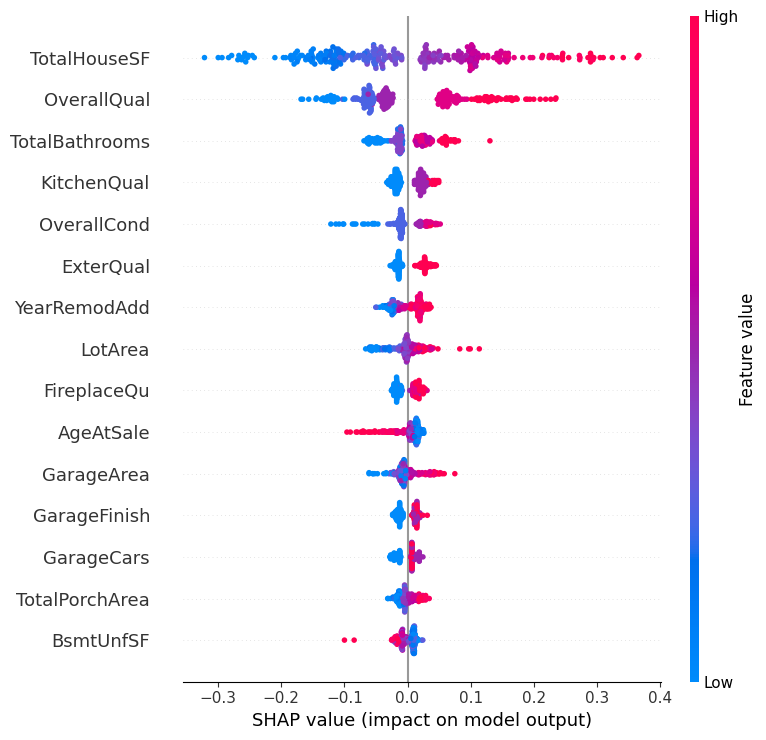

In [277]:
#SHAP
import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_validation)

shap.summary_plot(shap_values, X_validation, max_display =15)

In [279]:
#predictions on test dataset
predicted_sales = best_model.predict(test_df_encoded)

In [280]:
predictions_in_dollars = np.expm1(predicted_sales)

In [282]:
test_X = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')


In [283]:
submission_df = pd.DataFrame({
    'Id' : test_X['Id'],
    'SalePrice' : predictions_in_dollars
})

In [284]:
submission_df.head()

,Id,SalePrice
0,1461,120564.023438
1,1462,161274.375000
2,1463,186399.437500
3,1464,195768.343750
4,1465,196827.343750


In [286]:
submission_df.to_csv('submission.csv', index = False)